# Faster R-CNN


## ARCHITECTURE OF DOUBLE SHOT DETECTOR

Image

   ↓

Backbone (CNN)(RESNET)

   ↓

RPN (Region Proposal Network)

   ↓

ROI Pooling

   ↓

Classifier + Box Regressor


In [ ]:
# importing the necessary libraries
import torch           # deep learning used for cpu's and gpu's
import torchvision     # pre-trained models used for image and videos
import cv2             # image handling
from torchvision.transforms import functional as F # img,viseo --- pytorch
from google.colab.patches import cv2_imshow
from torchvision.ops import nms

In [ ]:
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
model.eval()
#fasterrcnn → two-stage detector
#resnet50 → backbone CNN
#fpn(Feature pyramid network) → handles small, medium & large objects
#pretrained=True → already trained

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 164MB/s]


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [ ]:
# Reading the image
image = cv2.imread("/content/doggo.jpg")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [ ]:
# Optional: improves small-object detection
image_rgb = cv2.resize(image_rgb, None, fx=1.5, fy=1.5)

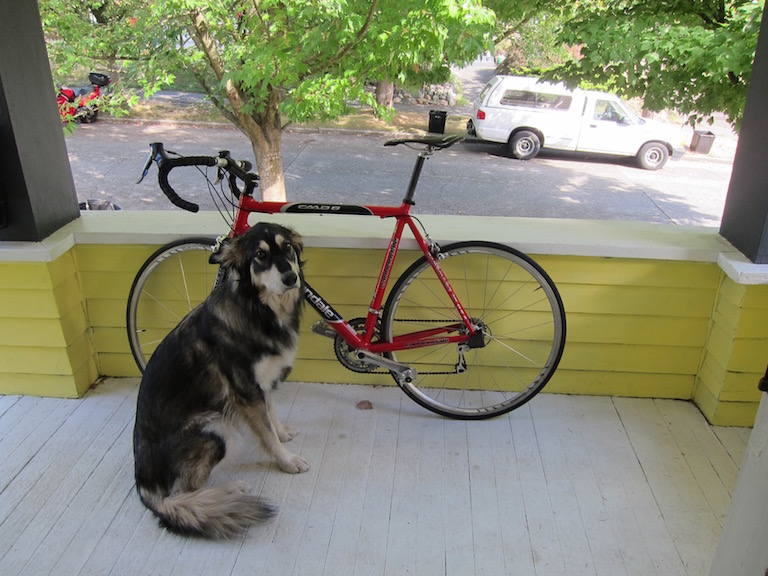

In [ ]:
cv2_imshow(image)

In [ ]:
# Convert image to tensor
img_tensor = F.to_tensor(image_rgb)

In [ ]:
# Model prediction (SECOND STAGE happens here)
with torch.no_grad():
    predictions = model([img_tensor])[0]

In [ ]:
COCO_CLASSES = [
    "__background__", "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light", "fire hydrant",
    "stop sign", "parking meter", "bench", "bird", "cat", "dog", "horse",
    "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee", "skis",
    "snowboard", "sports ball", "kite", "baseball bat", "baseball glove",
    "skateboard", "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza",
    "donut", "cake", "chair", "couch", "potted plant", "bed",
    "dining table", "toilet", "tv", "laptop", "mouse", "remote",
    "keyboard", "cell phone", "microwave", "oven", "toaster", "sink",
    "refrigerator", "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]


In [ ]:
CONF_THRESHOLD = 0.8   # confidence
NMS_THRESHOLD  = 0.3   # remove duplicates
TOP_K          = 10    # max objects to show

In [ ]:
# DRAW BOUNDING BOXES
boxes  = predictions["boxes"]
scores = predictions["scores"]
labels = predictions["labels"]

In [ ]:
# Non-Maximum Suppression
keep = nms(boxes, scores, iou_threshold=NMS_THRESHOLD)
keep = keep[:TOP_K]

In [ ]:
image_draw = image_rgb.copy()

In [ ]:
for idx in keep:
    if scores[idx] < CONF_THRESHOLD:
        continue

    x1, y1, x2, y2 = map(int, boxes[idx])
    label = labels[idx]

    class_name = COCO_CLASSES[label] if label < len(COCO_CLASSES) else "object"

    cv2.rectangle(image_draw, (x1, y1), (x2, y2), (0,255,0), 2)
    cv2.putText(
        image_draw,
        f"{class_name} {scores[idx]:.2f}",
        (x1, y1 - 8),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (0,0,0),
        2
    )

GOOD OBJECT DETECTION OUTPUT


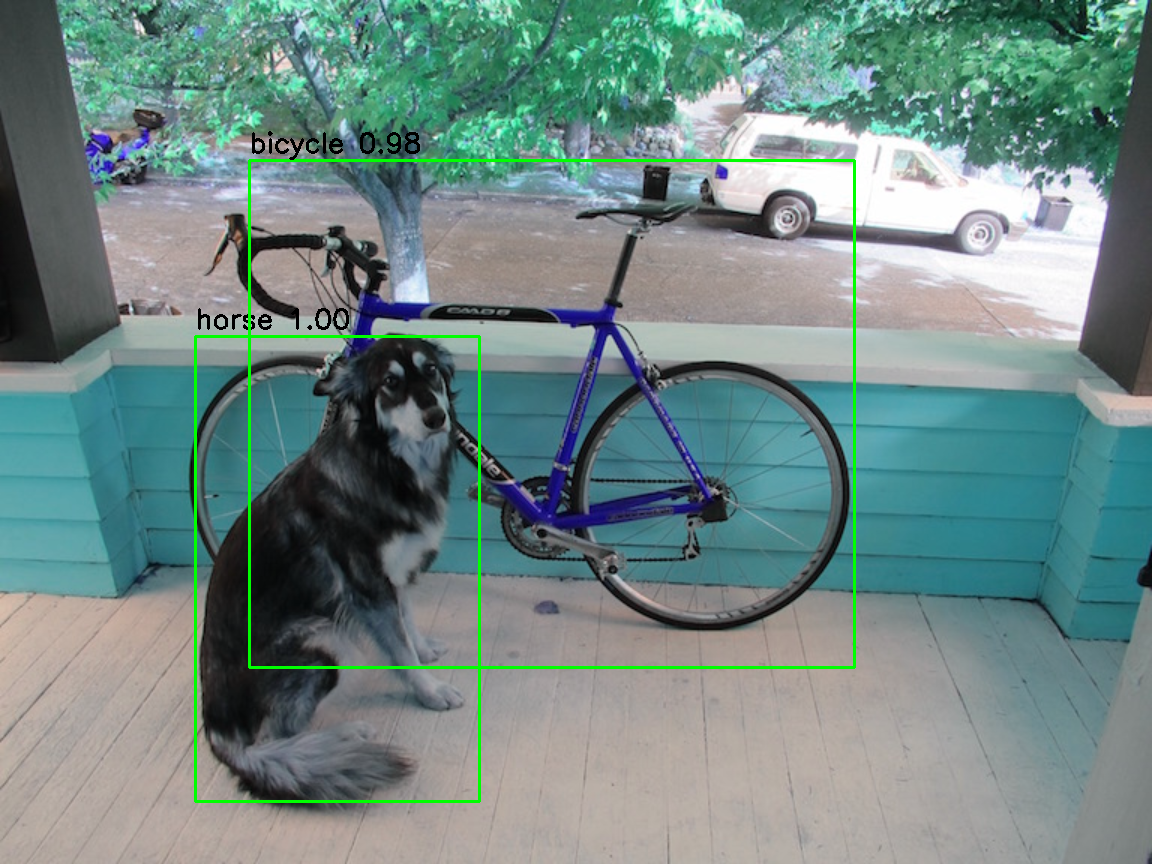

In [ ]:
print("GOOD OBJECT DETECTION OUTPUT")
cv2_imshow(image_draw)